In [ ]:
om google.colab import files

uploaded = files.upload()

Saving Data_Cleaning_Reporting_Automation_Dataset.xlsx to Data_Cleaning_Reporting_Automation_Dataset.xlsx


In [ ]:
import pandas as pd

df = pd.read_excel("Data_Cleaning_Reporting_Automation_Dataset.xlsx")

df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Product,Category,Region,City,Quantity,Unit_Price,Discount_Percent,Payment_Method,Order_Status,Sales_Amount,Profit
0,ORD102966,2025-12-26 20:57:32.351,CUST1025,Arun Kumar,Printer,Office Equipment,East,Pune,1,2499,10.0,Cash,Completed,2249.10,491.78
1,ORD102958,2025-12-25 21:39:18.786,CUST1387,Priya Sharma,Keyboard,Electronics,North,Bengaluru,2,29999,0.0,Cash,Pending,59998.00,5052.74
2,ORD100217,2025-01-27 05:12:06.242,CUST1233,Arun Kumar,Printer,Accessories,East,Mumbai,5,799,25.0,UPI,Completed,2996.25,429.04
3,ORD102299,2025-10-06 22:00:26.409,CUST1314,Karthik M,Smartphone,Office Equipment,East,Mumbai,4,2499,20.0,Credit Card,Completed,7996.80,2254.35
4,ORD101709,2025-07-27 07:21:16.025,CUST1406,Vijay Kumar,Headphones,Accessories,South,Pune,3,1499,0.0,Debit Card,Cancelled,4497.00,535.75


In [ ]:
import os

os.listdir()

['.config', 'Data_Cleaning_Reporting_Automation_Dataset.xlsx', 'sample_data']

In [ ]:
df.shape

(3025, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3025 entries, 0 to 3024
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          3025 non-null   object        
 1   Order_Date        3025 non-null   datetime64[ns]
 2   Customer_ID       3025 non-null   object        
 3   Customer_Name     2980 non-null   object        
 4   Product           3025 non-null   object        
 5   Category          3025 non-null   object        
 6   Region            2979 non-null   object        
 7   City              3025 non-null   object        
 8   Quantity          3025 non-null   int64         
 9   Unit_Price        3025 non-null   int64         
 10  Discount_Percent  2980 non-null   float64       
 11  Payment_Method    2979 non-null   object        
 12  Order_Status      3025 non-null   object        
 13  Sales_Amount      3025 non-null   float64       
 14  Profit            3025 n

In [ ]:
missing_values = df.isnull().sum()

print(missing_values)

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name       45
Product              0
Category             0
Region              46
City                 0
Quantity             0
Unit_Price           0
Discount_Percent    45
Payment_Method      46
Order_Status         0
Sales_Amount         0
Profit               0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Order_ID            0.000000
Order_Date          0.000000
Customer_ID         0.000000
Customer_Name       1.487603
Product             0.000000
Category            0.000000
Region              1.520661
City                0.000000
Quantity            0.000000
Unit_Price          0.000000
Discount_Percent    1.487603
Payment_Method      1.520661
Order_Status        0.000000
Sales_Amount        0.000000
Profit              0.000000
dtype: float64


In [ ]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_report = missing_report[missing_report["Missing_Count"] > 0]

missing_report

,Missing_Count,Missing_Percentage
Customer_Name,45,1.49
Region,46,1.52
Discount_Percent,45,1.49
Payment_Method,46,1.52


In [ ]:
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")

df["Region"] = df["Region"].fillna("Unknown")

df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")

df["Discount_Percent"] = df["Discount_Percent"].fillna(
    df["Discount_Percent"].median()
)

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Product,0
Category,0
Region,0
City,0
Quantity,0
Unit_Price,0


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 25


In [ ]:
duplicates = df[df.duplicated(keep=False)]

duplicates

,Order_ID,Order_Date,Customer_ID,Customer_Name,Product,Category,Region,City,Quantity,Unit_Price,Discount_Percent,Payment_Method,Order_Status,Sales_Amount,Profit
20,ORD102038,2025-09-05 05:43:18.866,CUST1437,Karthik M,Printer,Office Equipment,East,Kolkata,3,999,5.0,Net Banking,Completed,2847.15,349.66
128,ORD102265,2025-10-02 18:57:58.760,CUST1122,Karthik M,Tablet,Office Equipment,Unknown,Coimbatore,1,9999,10.0,UPI,Completed,8999.10,1028.87
282,ORD102215,2025-09-26 17:19:03.981,CUST1320,Priya Sharma,Smartphone,Office Equipment,West,Delhi,1,9999,0.0,Cash,Completed,9999.00,898.17
283,ORD102038,2025-09-05 05:43:18.866,CUST1437,Karthik M,Printer,Office Equipment,East,Kolkata,3,999,5.0,Net Banking,Completed,2847.15,349.66
305,ORD100892,2025-04-19 03:27:25.749,CUST1242,Ananya S,Tablet,Electronics,East,Mumbai,4,29999,0.0,Credit Card,Cancelled,119996.00,17086.25
317,ORD102215,2025-09-26 17:19:03.981,CUST1320,Priya Sharma,Smartphone,Office Equipment,West,Delhi,1,9999,0.0,Cash,Completed,9999.00,898.17
335,ORD101397,2025-06-19 10:30:27.009,CUST1141,Rahul Singh,Tablet,Accessories,East,Chennai,1,9999,25.0,Cash,Completed,7499.25,2237.09
409,ORD102499,2025-10-31 04:36:05.522,CUST1242,Arun Kumar,Keyboard,Office Equipment,South,Chennai,5,799,0.0,Net Banking,Completed,3995.00,1057.87
439,ORD101236,2025-05-30 21:31:09.023,CUST1261,Priya Sharma,Laptop,Office Equipment,West,Chennai,2,9999,5.0,Credit Card,Completed,18998.10,4542.84
441,ORD101477,2025-06-29 03:32:42.654,CUST1285,Vijay Kumar,Mouse,Office Equipment,East,Kolkata,3,4999,10.0,Unknown,Cancelled,13497.30,1561.26


In [ ]:
df = df.drop_duplicates()

In [ ]:
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Rows after cleaning:", len(df))

Duplicate rows after cleaning: 0
Rows after cleaning: 3000


In [ ]:
print(df["Region"].value_counts(dropna=False))

Region
North      800
East       728
South      710
West       699
Unknown     45
South        9
 SOUTH       5
south        4
Name: count, dtype: int64


In [ ]:
print(df["Payment_Method"].value_counts(dropna=False))

Payment_Method
Credit Card    630
Cash           594
UPI            590
Debit Card     576
Net Banking    547
Unknown         45
upi              8
UPI              7
 UPI             3
Name: count, dtype: int64


In [ ]:
print(df["Order_Status"].value_counts(dropna=False))

Order_Status
Completed     1722
Cancelled      632
Pending        628
Completed        6
 COMPLETED       6
completed        6
Name: count, dtype: int64


In [ ]:
df["Region"] = df["Region"].str.strip().str.title()

df["Payment_Method"] = df["Payment_Method"].str.strip().str.title()

df["Order_Status"] = df["Order_Status"].str.strip().str.title()

In [ ]:
print("Region:")
print(df["Region"].unique())

print("\nPayment Method:")
print(df["Payment_Method"].unique())

print("\nOrder Status:")
print(df["Order_Status"].unique())

Region:
['East' 'North' 'South' 'West' 'Unknown']

Payment Method:
['Cash' 'Upi' 'Credit Card' 'Debit Card' 'Net Banking' 'Unknown']

Order Status:
['Completed' 'Pending' 'Cancelled']


In [ ]:
print("Invalid Quantity:")
print(df[df["Quantity"] <= 0])

Invalid Quantity:
       Order_ID              Order_Date Customer_ID Customer_Name     Product  \
127   ORD102399 2025-10-19 01:18:15.965    CUST1282     Divya Raj      Laptop   
671   ORD102179 2025-09-22 08:27:02.941    CUST1349  Priya Sharma       Mouse   
1261  ORD100280 2025-02-03 20:43:08.063    CUST1098     Karthik M  Smartphone   
1322  ORD100680 2025-03-24 09:54:26.289    CUST1268  Priya Sharma     Printer   
1592  ORD102218 2025-09-27 02:03:24.068    CUST1095  Priya Sharma       Mouse   
2084  ORD101467 2025-06-27 22:24:55.699    CUST1251   Vijay Kumar  Headphones   
2361  ORD102760 2025-12-01 20:53:13.064    CUST1293       Sneha R     Printer   
2664  ORD102392 2025-10-18 04:54:49.096    CUST1237   Vijay Kumar      Laptop   
2751  ORD101515 2025-07-03 18:14:17.086    CUST1257      Ananya S      Tablet   
2941  ORD100063 2025-01-08 12:36:15.125    CUST1053     Karthik M    Keyboard   
2992  ORD102719 2025-11-26 21:27:18.546    CUST1220     Divya Raj       Mouse   
3019  ORD1

In [ ]:
print("Invalid Discount:")
print(df[
    (df["Discount_Percent"] < 0) |
    (df["Discount_Percent"] > 100)
])

Invalid Discount:
       Order_ID              Order_Date Customer_ID Customer_Name     Product  \
139   ORD100796 2025-04-07 11:48:42.974    CUST1317     Divya Raj  Headphones   
214   ORD100323 2025-02-09 01:58:35.972    CUST1369   Rahul Singh     Printer   
542   ORD101193 2025-05-25 16:15:41.114    CUST1335       Sneha R    Keyboard   
543   ORD101571 2025-07-10 13:21:52.037    CUST1182   Vijay Kumar    Keyboard   
1089  ORD101885 2025-08-17 16:02:14.445    CUST1344    Arun Kumar     Monitor   
1541  ORD102829 2025-12-10 05:52:55.058    CUST1130   Vijay Kumar       Mouse   
1987  ORD101202 2025-05-26 18:28:41.374    CUST1335    Arun Kumar    Keyboard   
2020  ORD102321 2025-10-09 14:05:33.711    CUST1173  Priya Sharma     Printer   
2670  ORD102387 2025-10-17 14:20:55.619    CUST1186     Divya Raj     Monitor   
2677  ORD100853 2025-04-14 09:51:04.622    CUST1008     Divya Raj    Keyboard   

              Category Region        City  Quantity  Unit_Price  \
139        Accessories 

In [ ]:
print("Invalid Unit Price:")
print(df[df["Unit_Price"] <= 0])

Invalid Unit Price:
Empty DataFrame
Columns: [Order_ID, Order_Date, Customer_ID, Customer_Name, Product, Category, Region, City, Quantity, Unit_Price, Discount_Percent, Payment_Method, Order_Status, Sales_Amount, Profit]
Index: []


In [ ]:
print("Invalid Quantity:")
print(df[df["Quantity"] <= 0])

Invalid Quantity:
       Order_ID              Order_Date Customer_ID Customer_Name     Product  \
127   ORD102399 2025-10-19 01:18:15.965    CUST1282     Divya Raj      Laptop   
671   ORD102179 2025-09-22 08:27:02.941    CUST1349  Priya Sharma       Mouse   
1261  ORD100280 2025-02-03 20:43:08.063    CUST1098     Karthik M  Smartphone   
1322  ORD100680 2025-03-24 09:54:26.289    CUST1268  Priya Sharma     Printer   
1592  ORD102218 2025-09-27 02:03:24.068    CUST1095  Priya Sharma       Mouse   
2084  ORD101467 2025-06-27 22:24:55.699    CUST1251   Vijay Kumar  Headphones   
2361  ORD102760 2025-12-01 20:53:13.064    CUST1293       Sneha R     Printer   
2664  ORD102392 2025-10-18 04:54:49.096    CUST1237   Vijay Kumar      Laptop   
2751  ORD101515 2025-07-03 18:14:17.086    CUST1257      Ananya S      Tablet   
2941  ORD100063 2025-01-08 12:36:15.125    CUST1053     Karthik M    Keyboard   
2992  ORD102719 2025-11-26 21:27:18.546    CUST1220     Divya Raj       Mouse   
3019  ORD1

In [ ]:
print("Invalid Discount:")
print(df[
    (df["Discount_Percent"] < 0) |
    (df["Discount_Percent"] > 100)
])

Invalid Discount:
       Order_ID              Order_Date Customer_ID Customer_Name     Product  \
139   ORD100796 2025-04-07 11:48:42.974    CUST1317     Divya Raj  Headphones   
214   ORD100323 2025-02-09 01:58:35.972    CUST1369   Rahul Singh     Printer   
542   ORD101193 2025-05-25 16:15:41.114    CUST1335       Sneha R    Keyboard   
543   ORD101571 2025-07-10 13:21:52.037    CUST1182   Vijay Kumar    Keyboard   
1089  ORD101885 2025-08-17 16:02:14.445    CUST1344    Arun Kumar     Monitor   
1541  ORD102829 2025-12-10 05:52:55.058    CUST1130   Vijay Kumar       Mouse   
1987  ORD101202 2025-05-26 18:28:41.374    CUST1335    Arun Kumar    Keyboard   
2020  ORD102321 2025-10-09 14:05:33.711    CUST1173  Priya Sharma     Printer   
2670  ORD102387 2025-10-17 14:20:55.619    CUST1186     Divya Raj     Monitor   
2677  ORD100853 2025-04-14 09:51:04.622    CUST1008     Divya Raj    Keyboard   

              Category Region        City  Quantity  Unit_Price  \
139        Accessories 

In [ ]:
df = df[df["Quantity"] > 0]

In [ ]:
df = df[
    (df["Discount_Percent"] >= 0) &
    (df["Discount_Percent"] <= 100)
]

In [ ]:
print("Rows after removing invalid values:", len(df))

print("Invalid Quantity:", (df["Quantity"] <= 0).sum())

print(
    "Invalid Discount:",
    ((df["Discount_Percent"] < 0) | (df["Discount_Percent"] > 100)).sum()
)

Rows after removing invalid values: 2978
Invalid Quantity: 0
Invalid Discount: 0


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
Product             0
Category            0
Region              0
City                0
Quantity            0
Unit_Price          0
Discount_Percent    0
Payment_Method      0
Order_Status        0
Sales_Amount        0
Profit              0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Invalid Quantity:", (df["Quantity"] <= 0).sum())

Invalid Quantity: 0


In [ ]:
print(
    "Invalid Discount:",
    ((df["Discount_Percent"] < 0) |
     (df["Discount_Percent"] > 100)).sum()
)

Invalid Discount: 0


In [ ]:
df.dtypes

,0
Order_ID,object
Order_Date,datetime64[ns]
Customer_ID,object
Customer_Name,object
Product,object
Category,object
Region,object
City,object
Quantity,int64
Unit_Price,int64


In [ ]:
df["Sales_Amount"] = (
    df["Quantity"] *
    df["Unit_Price"] *
    (1 - df["Discount_Percent"] / 100)
).round(2)

In [ ]:
df.to_excel(
    "Cleaned_Data_Cleaning_Reporting_Automation.xlsx",
    index=False
)

In [ ]:
total_revenue = df["Sales_Amount"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

print("===== SALES REPORT =====")
print("Total Revenue       :", round(total_revenue, 2))
print("Total Profit        :", round(total_profit, 2))
print("Total Orders        :", total_orders)
print("Total Customers     :", total_customers)
print("Total Quantity Sold :", total_quantity)
print("Average Order Value :", round(average_order_value, 2))

===== SALES REPORT =====
Total Revenue       : 50446607.0
Total Profit        : 9476701.22
Total Orders        : 2978
Total Customers     : 450
Total Quantity Sold : 8947
Average Order Value : 16939.76


In [ ]:
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_report = (
    df.groupby("Month")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

monthly_report

,Month,Revenue,Profit,Orders
0,2025-01,4348065.80,831133.55,255
1,2025-02,4032542.40,781255.97,229
2,2025-03,3876164.15,733206.67,253
3,2025-04,4696724.25,902864.96,245
4,2025-05,4230006.35,807489.94,254
5,2025-06,3289628.80,596196.41,246
6,2025-07,4276551.95,782921.31,253
7,2025-08,4285085.85,805490.16,255
8,2025-09,4078672.15,793314.46,245
9,2025-10,4701072.45,894726.14,251


In [ ]:
region_report = (
    df.groupby("Region")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

region_report

,Region,Revenue,Profit,Orders
1,North,12669020.90,2340225.91,794
2,South,12482122.15,2391684.85,722
0,East,12345757.45,2273108.35,724
4,West,12216563.90,2323285.47,693
3,Unknown,733142.60,148396.64,45


In [ ]:
category_report = (
    df.groupby("Category")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

category_report

,Category,Revenue,Profit,Orders
0,Accessories,17014211.1,3284680.74,1042
1,Electronics,16896429.6,3013836.70,977
2,Office Equipment,16535966.3,3178183.78,959


In [ ]:
top_products = (
    df.groupby("Product")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
      .head(10)
)

top_products

,Product,Revenue,Profit,Quantity
7,Tablet,7309588.45,1419675.99,1168
5,Printer,6934450.50,1242608.04,1190
4,Mouse,6618064.30,1179237.71,1178
1,Keyboard,6463250.70,1235095.81,1127
0,Headphones,6013642.35,1102008.57,1117
6,Smartphone,5907455.15,1110865.01,1059
3,Monitor,5810965.75,1131840.04,1108
2,Laptop,5389189.80,1055370.05,1000


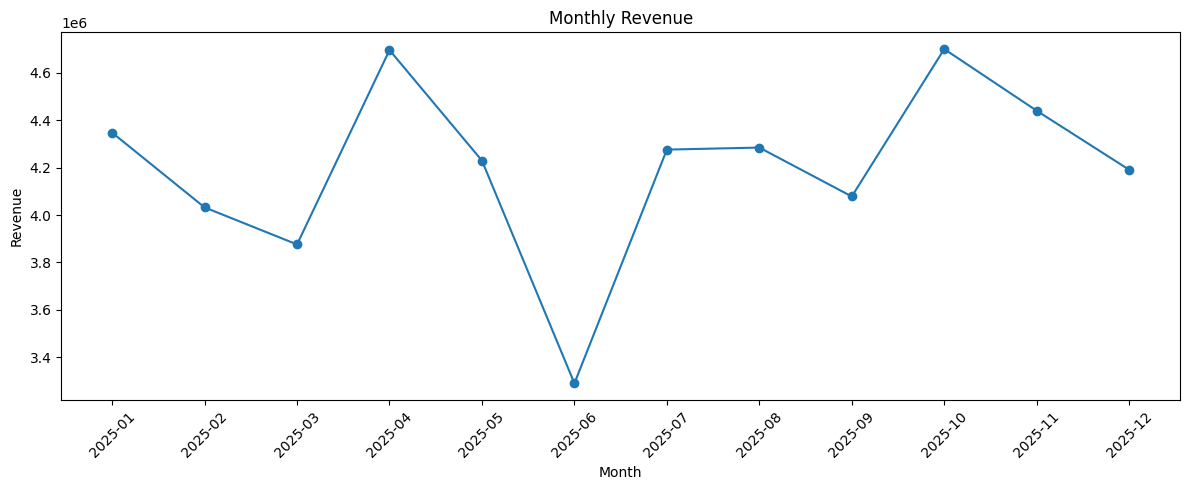

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_report["Month"],
    monthly_report["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

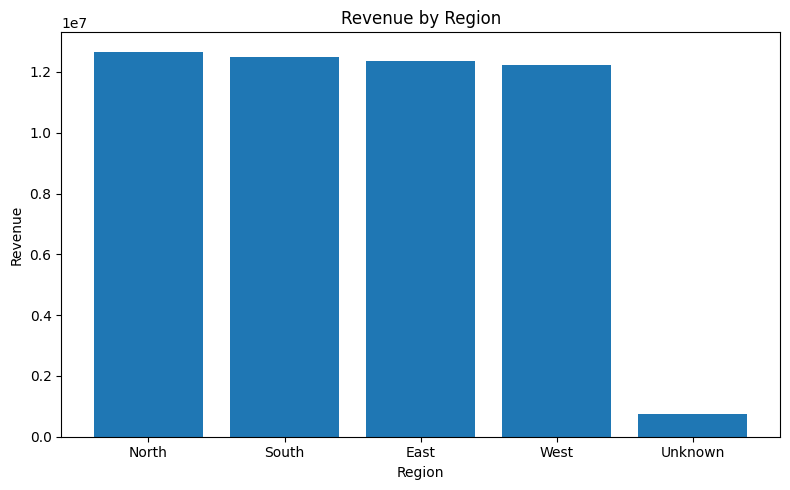

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_report["Region"],
    region_report["Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

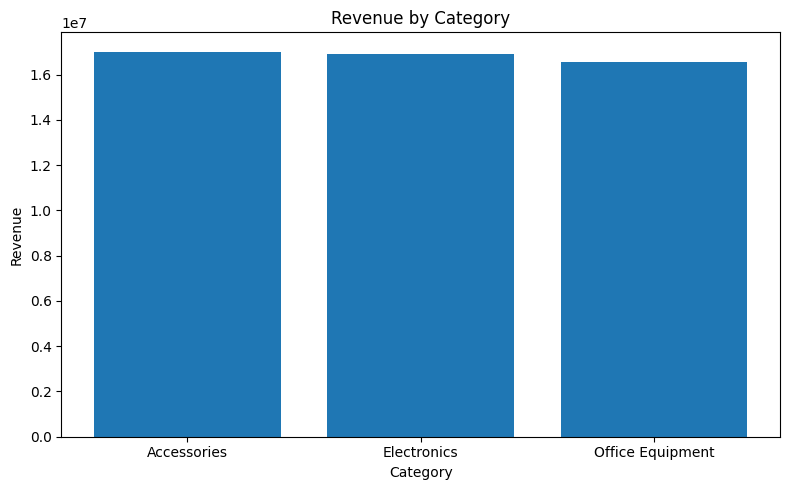

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_report["Category"],
    category_report["Revenue"]
)

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. KPI Summary
total_revenue = df["Sales_Amount"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Quantity Sold",
        "Average Order Value"
    ],
    "Value": [
        round(total_revenue, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        total_quantity,
        round(average_order_value, 2)
    ]
})

# 2. Monthly Report
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_report = (
    df.groupby("Month")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

# 3. Region Report
region_report = (
    df.groupby("Region")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

# 4. Category Report
category_report = (
    df.groupby("Category")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

# 5. Top 10 Products
top_products = (
    df.groupby("Product")
      .agg(
          Revenue=("Sales_Amount", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
      .head(10)
)

# 6. Export everything to one Excel file
with pd.ExcelWriter(
    "Automated_Sales_Report.xlsx",
    engine="openpyxl"
) as writer:

    summary.to_excel(writer, sheet_name="Summary", index=False)
    monthly_report.to_excel(writer, sheet_name="Monthly_Report", index=False)
    region_report.to_excel(writer, sheet_name="Region_Report", index=False)
    category_report.to_excel(writer, sheet_name="Category_Report", index=False)
    top_products.to_excel(writer, sheet_name="Top_Products", index=False)
    df.to_excel(writer, sheet_name="Cleaned_Data", index=False)

print("Automated report created successfully!")

Automated report created successfully!


In [ ]:
from google.colab import files

files.download("Automated_Sales_Report.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>